# Exercise 5

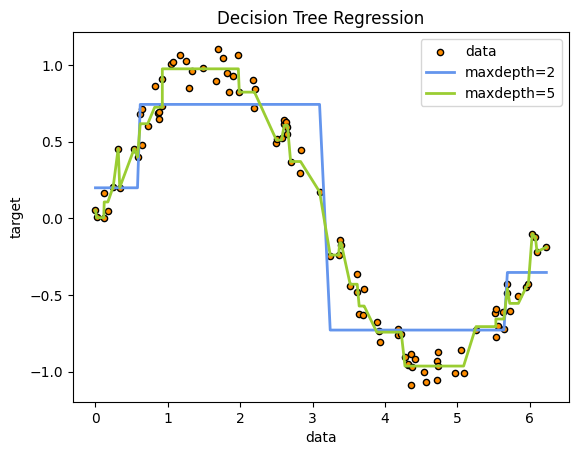

In [28]:
# Import the necessary modules and libraries
import numpy as np
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt

# Create a random dataset
rng = np.random.RandomState(1)
X = np.sort(6.3 * rng.rand(100, 1), axis=0)
y = np.sin(X).ravel()
y += 0.3 * (0.5 - rng.rand(len(X)))
# Fit regression model
regr_1 = DecisionTreeRegressor(max_depth=2)
regr_2 = DecisionTreeRegressor(max_depth=5)
regr_1.fit(X, y)
regr_2.fit(X, y)

# Predict
y_1 = regr_1.predict(X)
y_2 = regr_2.predict(X)

# Plot the results
plt.figure()
plt.scatter(X, y, s=20, edgecolor="black",
            c="darkorange", label="data")
plt.plot(X, y_1, color="cornflowerblue",
         label="maxdepth=2", linewidth=2)
plt.plot(X, y_2, color="yellowgreen", label="maxdepth=5", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()

In [31]:
def My_TreeRegressor(y, il, ir, max_depth, level=0):
    global yreg

    # init
    if level == 0:
        yreg = np.zeros(len(y))

    # stopping condition
    if level == max_depth or (ir - il) <= 1:
        yreg[il:ir] = np.mean(y[il:ir])
        return

    # find best split
    best_mse = np.inf
    best_i = il

    for i in range(il, ir): 
        left = y[il:i]
        right = y[i:ir]

        mse = mse = np.sum((left - np.mean(left))**2) + np.sum((right - np.mean(right))**2)

        if mse < best_mse:
            best_mse = mse
            best_i = i

    # recursion
    My_TreeRegressor(y, il, best_i, max_depth, level+1)
    My_TreeRegressor(y, best_i, ir, max_depth, level+1)

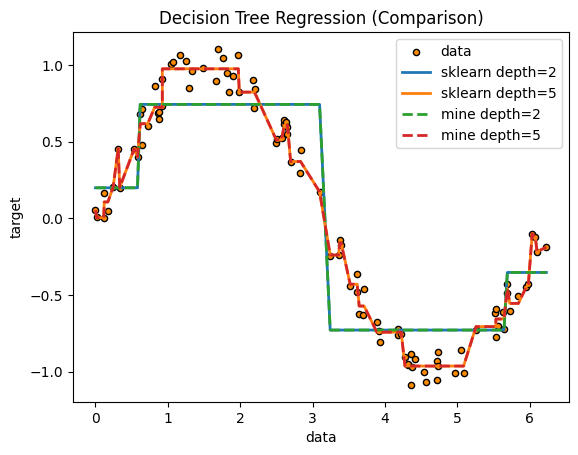

In [32]:
# Custom Tree model
My_TreeRegressor(y, 0, len(y), max_depth=2)
y_my_1 = yreg.copy()

My_TreeRegressor(y, 0, len(y), max_depth=5)
y_my_2 = yreg.copy()

# plot
plt.figure()
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="data")

plt.plot(X, y_1, label="sklearn depth=2", linewidth=2)
plt.plot(X, y_2, label="sklearn depth=5", linewidth=2)

plt.plot(X, y_my_1, "--", label="mine depth=2", linewidth=2)
plt.plot(X, y_my_2, "--", label="mine depth=5", linewidth=2)

plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression (Comparison)")
plt.legend()
plt.show()

The results overlap and are exactly the same.